# Spleen CT segmentation and volumetry

MSD Task09, 3D U-Net, then a multi-centre fine-tune on TotalSegmentator scans.

In [ ]:
!nvidia-smi


Wed Oct 14 16:01:45 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   58C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
!pip install -q "monai[nibabel]>=1.3" scikit-image


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 32.4 MB/s eta 0:00:00


In [ ]:
import torch, monai, nibabel
print("PyTorch :", torch.__version__)
print("MONAI   :", monai.__version__)
print("GPU     :", torch.cuda.is_available(), "-", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None")


PyTorch : 2.11.0+cu130
MONAI   : 1.6.1
GPU     : True - Tesla T4


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

import os
PROJECT_DIR = "/content/drive/MyDrive/spleen_project"
os.makedirs(PROJECT_DIR, exist_ok=True)
print("Project folder ready:", PROJECT_DIR)


Mounted at /content/drive
Project folder ready: /content/drive/MyDrive/spleen_project


## Configuration

In [ ]:
import os, glob, json, random, time
import numpy as np
import torch
import matplotlib.pyplot as plt
import nibabel as nib

from monai.apps import download_and_extract
from monai.utils import set_determinism

SEED = 42
set_determinism(seed=SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

DATA_DIR    = "/content/data"
RESULTS_DIR = "/content/drive/MyDrive/spleen_project"
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

HU_MIN, HU_MAX = -57, 164
SPACING  = (1.5, 1.5, 2.0)
ROI_SIZE = (96, 96, 96)

print("Device:", device)


Device: cuda


## Data

In [ ]:
url = "https://msd-for-monai.s3-us-west-2.amazonaws.com/Task09_Spleen.tar"
tar_path  = os.path.join(DATA_DIR, "Task09_Spleen.tar")
data_root = os.path.join(DATA_DIR, "Task09_Spleen")

if not os.path.exists(data_root):
    download_and_extract(url, tar_path, DATA_DIR)

images = sorted(glob.glob(os.path.join(data_root, "imagesTr", "*.nii.gz")))
labels = sorted(glob.glob(os.path.join(data_root, "labelsTr", "*.nii.gz")))
test_images = sorted(glob.glob(os.path.join(data_root, "imagesTs", "*.nii.gz")))

print(f"Training images : {len(images)}")
print(f"Training labels : {len(labels)}")
print(f"Unlabelled test : {len(test_images)}")


Task09_Spleen.tar: 1.50GB [01:03, 25.2MB/s]                            

2026-10-14 16:03:55,380 - INFO - Downloaded: /content/data/Task09_Spleen.tar
2026-10-14 16:03:55,381 - INFO - Writing into directory: /content/data.



/usr/local/lib/python3.13/dist-packages/monai/apps/utils.py:273: UserWarning: No hash value provided for /tmp/tmpji2afp7i/Task09_Spleen.tar; file integrity is NOT verified.
  if not check_hash(tmp_name, hash_val, hash_type):


Training images : 41
Training labels : 41
Unlabelled test : 20


## A first look at the scans

In [ ]:
img = nib.load(images[0])
lbl = nib.load(labels[0])
img_data = img.get_fdata()
lbl_data = lbl.get_fdata()

print("File          :", os.path.basename(images[0]))
print("Shape (H,W,D) :", img_data.shape)
print("Voxel spacing :", np.round(img.header.get_zooms(), 2), "mm")
print("HU range      :", img_data.min(), "to", img_data.max())
print("Label values  :", np.unique(lbl_data))
print(f"Spleen voxels : {100 * lbl_data.mean():.2f}% of the volume")


File          : spleen_10.nii.gz
Shape (H,W,D) : (512, 512, 55)
Voxel spacing : [0.98 0.98 5.  ] mm
HU range      : -1024.0 to 3072.0
Label values  : [0. 1.]
Spleen voxels : 0.37% of the volume


Slices per scan      : 31 to 168
Slice spacing (mm)   : 1.50 to 8.00
Spleen volume (mL)   : 56 to 502  (mean 243)
Spleen % of volume   : 0.08% to 1.33%


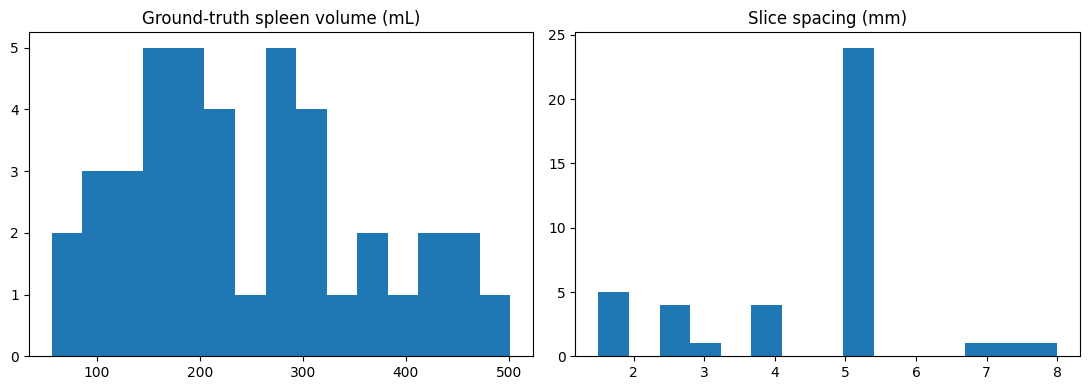

In [ ]:
rows = []
for img_p, lbl_p in zip(images, labels):
    im, lb = nib.load(img_p), nib.load(lbl_p)
    sp = im.header.get_zooms()
    lb_data = lb.get_fdata()
    vol_ml = lb_data.sum() * np.prod(sp) / 1000
    rows.append((os.path.basename(img_p), im.shape, sp, vol_ml, 100 * lb_data.mean()))

slices   = np.array([r[1][2] for r in rows])
z_space  = np.array([r[2][2] for r in rows])
volumes  = np.array([r[3] for r in rows])
fraction = np.array([r[4] for r in rows])

print(f"Slices per scan      : {slices.min()} to {slices.max()}")
print(f"Slice spacing (mm)   : {z_space.min():.2f} to {z_space.max():.2f}")
print(f"Spleen volume (mL)   : {volumes.min():.0f} to {volumes.max():.0f}  (mean {volumes.mean():.0f})")
print(f"Spleen % of volume   : {fraction.min():.2f}% to {fraction.max():.2f}%")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(volumes, bins=15); ax[0].set_title("Ground-truth spleen volume (mL)")
ax[1].hist(z_space, bins=15); ax[1].set_title("Slice spacing (mm)")
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/eda_stats.png", dpi=120)
plt.show()


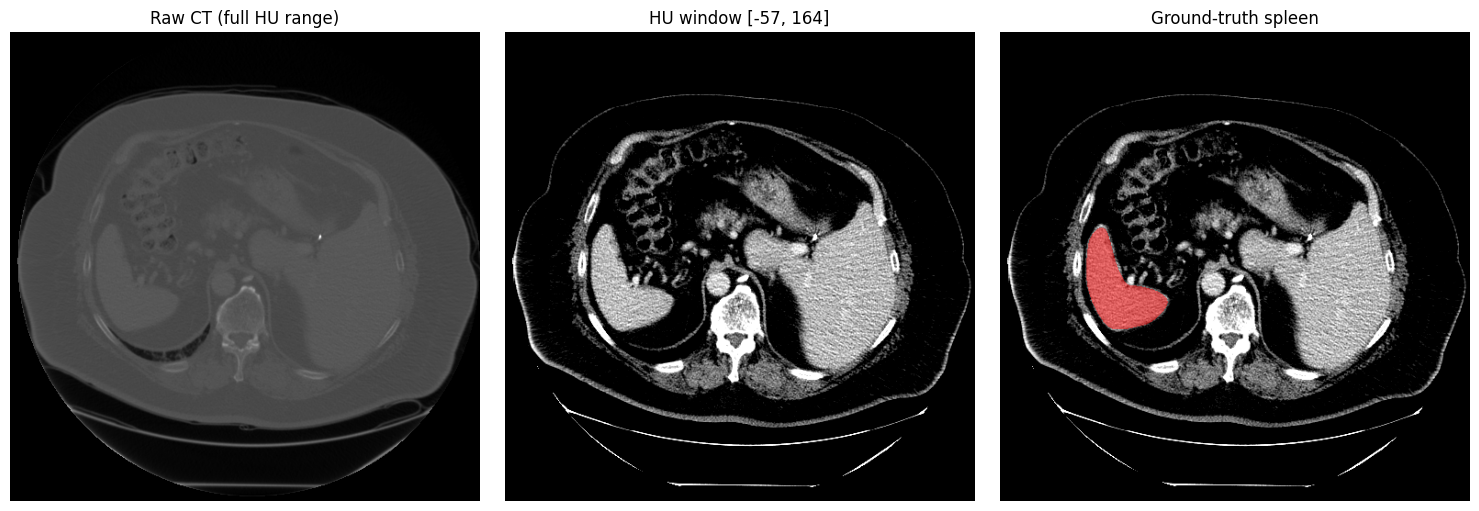

In [ ]:
z = int(lbl_data.sum(axis=(0, 1)).argmax())
raw      = img_data[:, :, z]
windowed = np.clip(raw, HU_MIN, HU_MAX)
mask     = lbl_data[:, :, z]

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(np.rot90(raw), cmap="gray");      ax[0].set_title("Raw CT (full HU range)")
ax[1].imshow(np.rot90(windowed), cmap="gray"); ax[1].set_title(f"HU window [{HU_MIN}, {HU_MAX}]")
ax[2].imshow(np.rot90(windowed), cmap="gray")
ax[2].imshow(np.rot90(np.ma.masked_where(mask == 0, mask)), cmap="autumn", alpha=0.5)
ax[2].set_title("Ground-truth spleen")
for a in ax: a.axis("off")
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/eda_example.png", dpi=120)
plt.show()


## Patient-level split

In [ ]:
data = [{"image": i, "label": l} for i, l in zip(images, labels)]
random.Random(SEED).shuffle(data)

test_files  = data[:6]
val_files   = data[6:12]
train_files = data[12:]
print(f"Train {len(train_files)} | Val {len(val_files)} | Test {len(test_files)}")

vol_of = {os.path.basename(r[0] if isinstance(r[0], str) else r[0]): r[3] for r in rows}
for name, files in [("Train", train_files), ("Val", val_files), ("Test", test_files)]:
    v = [vol_of[os.path.basename(f["image"])] for f in files]
    print(f"{name:5}: spleen volume {min(v):.0f}–{max(v):.0f} mL (mean {np.mean(v):.0f})")

with open(f"{RESULTS_DIR}/splits.json", "w") as f:
    json.dump({"train": train_files, "val": val_files, "test": test_files}, f, indent=2)


Train 29 | Val 6 | Test 6
Train: spleen volume 56–502 mL (mean 243)
Val  : spleen volume 78–426 mL (mean 262)
Test : spleen volume 119–450 mL (mean 224)


## Transforms

In [ ]:
from monai.transforms import (
    Compose, LoadImaged, EnsureChannelFirstd, Orientationd, Spacingd,
    ScaleIntensityRanged, CropForegroundd, RandCropByPosNegLabeld,
    RandFlipd, RandRotate90d, RandShiftIntensityd, EnsureTyped,
)

def base_transforms(keys, modes):
    return [
        LoadImaged(keys=keys),
        EnsureChannelFirstd(keys=keys),
        Orientationd(keys=keys, axcodes="RAS"),
        Spacingd(keys=keys, pixdim=SPACING, mode=modes),
        ScaleIntensityRanged(keys=["image"], a_min=HU_MIN, a_max=HU_MAX,
                             b_min=0.0, b_max=1.0, clip=True),
        CropForegroundd(keys=keys, source_key="image", allow_smaller=True),
    ]

train_transforms = Compose(base_transforms(["image", "label"], ("bilinear", "nearest")) + [
    RandCropByPosNegLabeld(keys=["image", "label"], label_key="label",
                           spatial_size=ROI_SIZE, pos=1, neg=1, num_samples=4,
                           image_key="image", image_threshold=0),
    RandFlipd(keys=["image", "label"], spatial_axis=[0], prob=0.10),
    RandFlipd(keys=["image", "label"], spatial_axis=[1], prob=0.10),
    RandFlipd(keys=["image", "label"], spatial_axis=[2], prob=0.10),
    RandRotate90d(keys=["image", "label"], prob=0.10, max_k=3),
    RandShiftIntensityd(keys=["image"], offsets=0.10, prob=0.50),
    EnsureTyped(keys=["image", "label"]),
])

val_transforms = Compose(base_transforms(["image", "label"], ("bilinear", "nearest")) + [
    EnsureTyped(keys=["image", "label"]),
])
print("Transforms ready")


Transforms ready


/usr/local/lib/python3.13/dist-packages/monai/utils/deprecate_utils.py:320: FutureWarning: monai.transforms.spatial.dictionary Orientationd.__init__:labels: Current default value of argument `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` was changed in version None from `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` to `labels=None`. Default value changed to None meaning that the transform now uses the 'space' of a meta-tensor, if applicable, to determine appropriate axis labels.
  warn_deprecated(argname, msg, warning_category)


In [ ]:
from monai.data import CacheDataset, DataLoader, decollate_batch
from monai.networks.nets import UNet
from monai.networks.layers import Norm
from monai.metrics import DiceMetric
from monai.inferers import sliding_window_inference
from monai.transforms import KeepLargestConnectedComponent, AsDiscrete

model = UNet(spatial_dims=3, in_channels=1, out_channels=2,
             channels=(16, 32, 64, 128, 256), strides=(2, 2, 2, 2),
             num_res_units=2, norm=Norm.BATCH).to(device)

FT_PATH = FT_DRIVE_PATH = f"{RESULTS_DIR}/best_model_ft.pth"
model.load_state_dict(torch.load(FT_PATH, map_location=device))
model.eval()

lcc = KeepLargestConnectedComponent(applied_labels=[1])
dice_metric = DiceMetric(include_background=False, reduction="mean")
voxel_ml = np.prod(SPACING) / 1000.0
print("Model loaded from Drive:", FT_PATH)


Model loaded from Drive: /content/drive/MyDrive/spleen_project/best_model_ft.pth


BEFORE preprocessing
  Shape   : (512, 512, 112)
  Spacing : [0.8 0.8 4. ] mm
AFTER preprocessing
  Shape   : (1, 272, 264, 223)  (channel, H, W, D)
  Spacing : [1.5 1.5 2. ] mm
  Values  : 0.0 to 1.0
  Labels  : [0.0, 1.0]


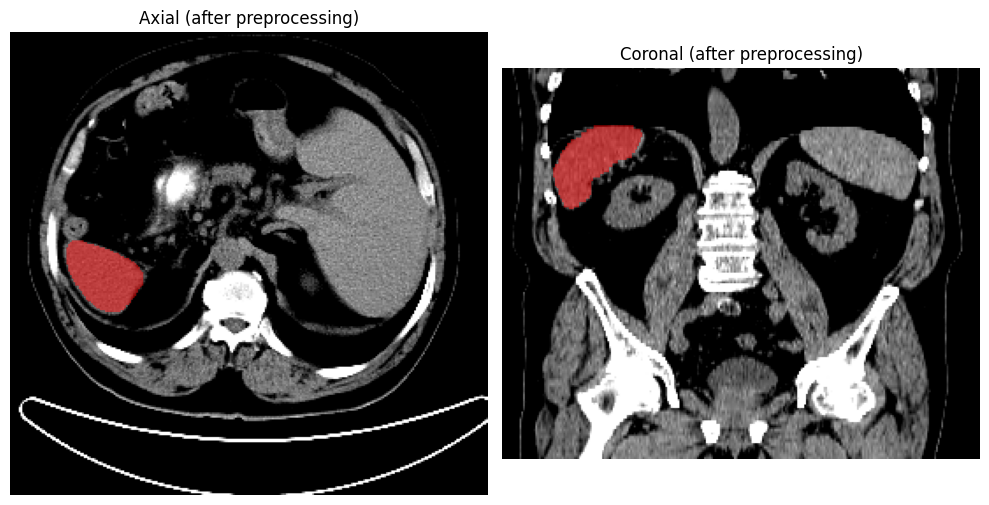

In [ ]:
before = nib.load(val_files[0]["image"])
after  = val_transforms(val_files[0])

print("BEFORE preprocessing")
print("  Shape   :", before.shape)
print("  Spacing :", np.round(before.header.get_zooms(), 2), "mm")
print("AFTER preprocessing")
print("  Shape   :", tuple(after["image"].shape), " (channel, H, W, D)")
print("  Spacing :", np.round(after["image"].pixdim.tolist(), 2), "mm")
print("  Values  :", float(after["image"].min()), "to", float(after["image"].max()))
print("  Labels  :", torch.unique(after["label"]).tolist())

img_a, lbl_a = after["image"][0].numpy(), after["label"][0].numpy()
z = int(lbl_a.sum(axis=(0, 1)).argmax())
y = int(lbl_a.sum(axis=(0, 2)).argmax())
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(np.rot90(img_a[:, :, z]), cmap="gray")
ax[0].imshow(np.rot90(np.ma.masked_where(lbl_a[:, :, z] == 0, lbl_a[:, :, z])), cmap="autumn", alpha=0.5)
ax[0].set_title("Axial (after preprocessing)")
ax[1].imshow(np.rot90(img_a[:, y, :]), cmap="gray")
ax[1].imshow(np.rot90(np.ma.masked_where(lbl_a[:, y, :] == 0, lbl_a[:, y, :])), cmap="autumn", alpha=0.5)
ax[1].set_title("Coronal (after preprocessing)")
for a in ax: a.axis("off")
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/preprocessing_example.png", dpi=120)
plt.show()


## Sanity checks before training

In [ ]:
from monai.data import CacheDataset, DataLoader

train_ds = CacheDataset(data=train_files, transform=train_transforms, cache_rate=1.0, num_workers=2)
val_ds   = CacheDataset(data=val_files,   transform=val_transforms,   cache_rate=1.0, num_workers=2)

train_loader = DataLoader(train_ds, batch_size=2, shuffle=True, num_workers=2)
val_loader   = DataLoader(val_ds,   batch_size=1, num_workers=2)

batch = next(iter(train_loader))
print("Image batch :", tuple(batch["image"].shape))
print("Label batch :", tuple(batch["label"].shape))
spleen_frac = batch["label"].float().mean(dim=(1, 2, 3, 4))
print("Spleen % in each patch:", [f"{100*f:.1f}%" for f in spleen_frac.tolist()])


Loading dataset: 100%|██████████| 6/6 [00:19<00:00,  3.27s/it]


Image batch : (8, 1, 96, 96, 96)
Label batch : (8, 1, 96, 96, 96)
Spleen % in each patch: ['0.0%', '0.0%', '0.0%', '0.0%', '10.5%', '11.5%', '2.2%', '0.4%']


## Model

In [ ]:
from monai.networks.nets import UNet
from monai.networks.layers import Norm

model = UNet(
    spatial_dims=3,
    in_channels=1,
    out_channels=2,
    channels=(16, 32, 64, 128, 256),
    strides=(2, 2, 2, 2),
    num_res_units=2,
    norm=Norm.BATCH,
).to(device)

print(f"Parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.2f} M")

batch = next(iter(train_loader))
with torch.no_grad():
    out = model(batch["image"].to(device))
print("Input shape: ", tuple(batch["image"].shape))
print("Output shape:", tuple(out.shape))


Parameters: 4.81 M
Input shape:  (8, 1, 96, 96, 96)
Output shape: (8, 2, 96, 96, 96)


In [ ]:
from monai.losses import DiceCELoss
from monai.metrics import DiceMetric
from monai.transforms import AsDiscrete

loss_fn     = DiceCELoss(to_onehot_y=True, softmax=True)
optimizer   = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-5)
dice_metric = DiceMetric(include_background=False, reduction="mean")

post_pred  = AsDiscrete(argmax=True, to_onehot=2)
post_label = AsDiscrete(to_onehot=2)

with torch.no_grad():
    loss = loss_fn(out, batch["label"].to(device))
print(f"Loss of untrained model: {loss.item():.3f}")


Loss of untrained model: 1.917


In [ ]:
from monai.data import decollate_batch
from monai.inferers import sliding_window_inference


## Training

In [ ]:
import time

MAX_EPOCHS = 200
VAL_EVERY  = 5
ROI_SIZE   = (96, 96, 96)

MODEL_PATH = "/content/results/best_model.pth"
DRIVE_PATH = "/content/drive/MyDrive/spleen_project/best_model.pth"
os.makedirs("/content/results", exist_ok=True)
os.makedirs(os.path.dirname(DRIVE_PATH), exist_ok=True)

best_dice, best_epoch = -1, -1
train_losses, val_dices = [], []
t0 = time.time()

for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    epoch_loss, steps = 0.0, 0
    for batch in train_loader:
        x, y = batch["image"].to(device), batch["label"].to(device)
        optimizer.zero_grad()
        out  = model(x)
        loss = loss_fn(out, y)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item(); steps += 1
    epoch_loss /= steps
    train_losses.append(epoch_loss)

    if epoch % VAL_EVERY == 0:
        model.eval()
        with torch.no_grad():
            for batch in val_loader:
                x, y = batch["image"].to(device), batch["label"].to(device)
                out = sliding_window_inference(x, ROI_SIZE, sw_batch_size=4,
                                               predictor=model, overlap=0.25)
                preds   = [post_pred(i)  for i in decollate_batch(out)]
                labels_ = [post_label(i) for i in decollate_batch(y)]
                dice_metric(y_pred=preds, y=labels_)
        val_dice = dice_metric.aggregate().item()
        dice_metric.reset()
        val_dices.append(val_dice)

        if val_dice > best_dice:
            best_dice, best_epoch = val_dice, epoch
            torch.save(model.state_dict(), MODEL_PATH)
            torch.save(model.state_dict(), DRIVE_PATH)

        mins = (time.time() - t0) / 60
        print(f"Epoch {epoch:3d} | loss {epoch_loss:.4f} | val Dice {val_dice:.4f} "
              f"| best {best_dice:.4f} (ep {best_epoch}) | {mins:.1f} min")

with open("/content/drive/MyDrive/spleen_project/history.json", "w") as f:
    json.dump({"train_losses": train_losses, "val_dices": val_dices,
               "best_dice": best_dice, "best_epoch": best_epoch}, f)

print(f"\nDone. Best val Dice {best_dice:.4f} at epoch {best_epoch}")


Epoch   5 | loss 1.3443 | val Dice 0.0188 | best 0.0188 (ep 5) | 1.5 min
Epoch  10 | loss 1.2259 | val Dice 0.0329 | best 0.0329 (ep 10) | 3.0 min
Epoch  15 | loss 1.0944 | val Dice 0.0591 | best 0.0591 (ep 15) | 4.6 min
Epoch  20 | loss 0.9785 | val Dice 0.1227 | best 0.1227 (ep 20) | 6.1 min
Epoch  25 | loss 0.8764 | val Dice 0.2465 | best 0.2465 (ep 25) | 7.6 min
Epoch  30 | loss 0.8123 | val Dice 0.2435 | best 0.2465 (ep 25) | 9.1 min
Epoch  35 | loss 0.7234 | val Dice 0.5278 | best 0.5278 (ep 35) | 10.7 min
Epoch  40 | loss 0.6725 | val Dice 0.7038 | best 0.7038 (ep 40) | 12.2 min
Epoch  45 | loss 0.5984 | val Dice 0.6111 | best 0.7038 (ep 40) | 13.7 min
Epoch  50 | loss 0.5601 | val Dice 0.6519 | best 0.7038 (ep 40) | 15.3 min
Epoch  55 | loss 0.5133 | val Dice 0.6653 | best 0.7038 (ep 40) | 16.8 min
Epoch  60 | loss 0.4842 | val Dice 0.7047 | best 0.7047 (ep 60) | 18.3 min
Epoch  65 | loss 0.4732 | val Dice 0.4897 | best 0.7047 (ep 60) | 19.9 min
Epoch  70 | loss 0.4384 | val Di

## Validation with post-processing

In [ ]:
from monai.transforms import KeepLargestConnectedComponent

EXTRA_EPOCHS = 150
lcc = KeepLargestConnectedComponent(applied_labels=[1])
FT_PATH       = "/content/results/best_model_ft.pth"
FT_DRIVE_PATH = "/content/drive/MyDrive/spleen_project/best_model_ft.pth"

model.load_state_dict(torch.load(MODEL_PATH))
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-5)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EXTRA_EPOCHS)

def validate():
    model.eval()
    with torch.no_grad():
        for batch in val_loader:
            x, y = batch["image"].to(device), batch["label"].to(device)
            out  = sliding_window_inference(x, ROI_SIZE, 4, model, overlap=0.25)
            pred = lcc(torch.argmax(out, dim=1, keepdim=True)[0]).unsqueeze(0)
            p1 = torch.cat([1 - pred, pred], dim=1).float()
            y1 = torch.cat([1 - y, y], dim=1).float()
            dice_metric(y_pred=p1, y=y1)
    d = dice_metric.aggregate().item()
    dice_metric.reset()
    return d

best_ft = validate()
best_ft_epoch = 0
print(f"Start (epoch-120 model, with LCC): val Dice {best_ft:.4f}")
torch.save(model.state_dict(), FT_PATH)
torch.save(model.state_dict(), FT_DRIVE_PATH)

ft_losses, ft_dices = [], []
t0 = time.time()
for epoch in range(1, EXTRA_EPOCHS + 1):
    model.train()
    epoch_loss, steps = 0.0, 0
    for batch in train_loader:
        x, y = batch["image"].to(device), batch["label"].to(device)
        optimizer.zero_grad()
        loss = loss_fn(model(x), y)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item(); steps += 1
    scheduler.step()
    ft_losses.append(epoch_loss / steps)

    if epoch % 5 == 0:
        d = validate()
        ft_dices.append(d)
        if d > best_ft:
            best_ft, best_ft_epoch = d, epoch
            torch.save(model.state_dict(), FT_PATH)
            torch.save(model.state_dict(), FT_DRIVE_PATH)
        print(f"FT {epoch:3d} | loss {ft_losses[-1]:.4f} | val Dice {d:.4f} "
              f"| best {best_ft:.4f} (ep {best_ft_epoch}) | lr {scheduler.get_last_lr()[0]:.1e} "
              f"| {(time.time()-t0)/60:.1f} min")

with open("/content/drive/MyDrive/spleen_project/history_ft.json", "w") as f:
    json.dump({"losses": ft_losses, "val_dices": ft_dices,
               "best": best_ft, "best_epoch": best_ft_epoch}, f)
print(f"\nDone. Best val Dice (LCC) {best_ft:.4f}")


Start (epoch-120 model, with LCC): val Dice 0.8723
FT   5 | loss 0.2886 | val Dice 0.7565 | best 0.8723 (ep 0) | lr 1.0e-04 | 1.6 min
FT  10 | loss 0.2755 | val Dice 0.7578 | best 0.8723 (ep 0) | lr 9.9e-05 | 3.1 min
FT  15 | loss 0.2490 | val Dice 0.8340 | best 0.8723 (ep 0) | lr 9.8e-05 | 4.7 min
FT  20 | loss 0.2439 | val Dice 0.8331 | best 0.8723 (ep 0) | lr 9.6e-05 | 6.2 min
FT  25 | loss 0.2451 | val Dice 0.7981 | best 0.8723 (ep 0) | lr 9.3e-05 | 7.8 min
FT  30 | loss 0.2244 | val Dice 0.7504 | best 0.8723 (ep 0) | lr 9.0e-05 | 9.4 min
FT  35 | loss 0.2293 | val Dice 0.7801 | best 0.8723 (ep 0) | lr 8.7e-05 | 10.9 min
FT  40 | loss 0.2774 | val Dice 0.7902 | best 0.8723 (ep 0) | lr 8.3e-05 | 12.4 min
FT  45 | loss 0.2341 | val Dice 0.7631 | best 0.8723 (ep 0) | lr 7.9e-05 | 14.0 min
FT  50 | loss 0.2621 | val Dice 0.9005 | best 0.9005 (ep 50) | lr 7.5e-05 | 15.6 min
FT  55 | loss 0.2340 | val Dice 0.8505 | best 0.9005 (ep 50) | lr 7.0e-05 | 17.1 min
FT  60 | loss 0.2490 | val Di

## Held-out test set

In [ ]:
from monai.metrics import MeanIoU, compute_hausdorff_distance

model.load_state_dict(torch.load(FT_PATH))
model.eval()

test_ds = CacheDataset(data=test_files, transform=val_transforms, cache_rate=1.0, num_workers=2)
test_loader = DataLoader(test_ds, batch_size=1)
voxel_ml = np.prod(SPACING) / 1000.0

rows, test_outputs = [], []
with torch.no_grad():
    for i, batch in enumerate(test_loader):
        x, y = batch["image"].to(device), batch["label"].to(device)
        out  = sliding_window_inference(x, ROI_SIZE, 4, model, overlap=0.25)
        raw  = torch.argmax(out, dim=1, keepdim=True)
        y1   = torch.cat([1 - y, y], dim=1).float()

        res = {}
        for tag, p in [("raw", raw), ("lcc", lcc(raw[0]).unsqueeze(0))]:
            p1 = torch.cat([1 - p, p], dim=1).float()
            res[tag] = dict(
                dice=DiceMetric(include_background=False)(p1, y1).item(),
                iou=MeanIoU(include_background=False)(p1, y1).item(),
                hd95=compute_hausdorff_distance(p1, y1, include_background=False,
                                                percentile=95, spacing=SPACING).item(),
                vol=p.sum().item() * voxel_ml)
        pred = lcc(raw[0]).unsqueeze(0)
        vol_gt = y.sum().item() * voxel_ml
        r = res["lcc"]
        rows.append(dict(case=os.path.basename(test_files[i]["image"]),
                         dice=r["dice"], iou=r["iou"], hd95_mm=r["hd95"],
                         dice_raw=res["raw"]["dice"], hd95_raw=res["raw"]["hd95"],
                         vol_pred_ml=r["vol"], vol_gt_ml=vol_gt,
                         vol_err_pct=100 * (r["vol"] - vol_gt) / vol_gt))
        test_outputs.append((x[0, 0].cpu().numpy(), y[0, 0].cpu().numpy(),
                             pred[0, 0].cpu().numpy()))

print(f"{'case':<18}{'Dice':>7}{'IoU':>7}{'HD95':>8}{'Dice raw':>10}{'HD95 raw':>10}"
      f"{'Pred mL':>9}{'GT mL':>8}{'Err %':>7}")
for r in rows:
    print(f"{r['case']:<18}{r['dice']:7.3f}{r['iou']:7.3f}{r['hd95_mm']:8.2f}"
          f"{r['dice_raw']:10.3f}{r['hd95_raw']:10.2f}"
          f"{r['vol_pred_ml']:9.1f}{r['vol_gt_ml']:8.1f}{r['vol_err_pct']:7.1f}")
print()
for k in ["dice", "iou", "hd95_mm", "dice_raw", "hd95_raw", "vol_err_pct"]:
    v = np.array([r[k] for r in rows])
    print(f"{k:>12}: mean {v.mean():.3f} ± {v.std():.3f}")

with open("/content/drive/MyDrive/spleen_project/test_metrics.json", "w") as f:
    json.dump(rows, f, indent=2)


Loading dataset: 100%|██████████| 6/6 [00:19<00:00,  3.20s/it]
/usr/local/lib/python3.13/dist-packages/monai/utils/deprecate_utils.py:220: FutureWarning: monai.metrics.utils get_mask_edges:always_return_as_numpy: Argument `always_return_as_numpy` has been deprecated since version 1.5.0. It will be removed in version 1.7.0. The option is removed and the return type will always be equal to the input type.
  warn_deprecated(argname, msg, warning_category)


case                 Dice    IoU    HD95  Dice raw  HD95 raw  Pred mL   GT mL  Err %
spleen_20.nii.gz    0.938  0.883    4.74     0.938      4.74    306.3   289.0    6.0
spleen_14.nii.gz    0.957  0.917    2.50     0.957      2.50    451.0   450.1    0.2
spleen_21.nii.gz    0.889  0.800   12.26     0.889     12.26    149.2   133.3   11.9
spleen_61.nii.gz    0.939  0.886    2.50     0.939      2.50    158.7   163.0   -2.7
spleen_44.nii.gz    0.798  0.664   12.00     0.798     12.00     86.7   119.4  -27.4
spleen_41.nii.gz    0.928  0.866    3.00     0.928      3.00    179.1   189.9   -5.7

        dice: mean 0.908 ± 0.053
         iou: mean 0.836 ± 0.085
     hd95_mm: mean 6.167 ± 4.283
    dice_raw: mean 0.908 ± 0.053
    hd95_raw: mean 6.167 ± 4.283
 vol_err_pct: mean -2.934 ± 12.352


## Where it goes wrong

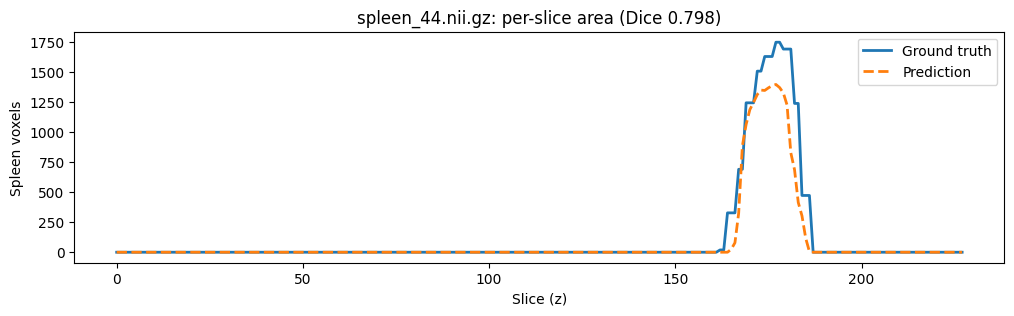

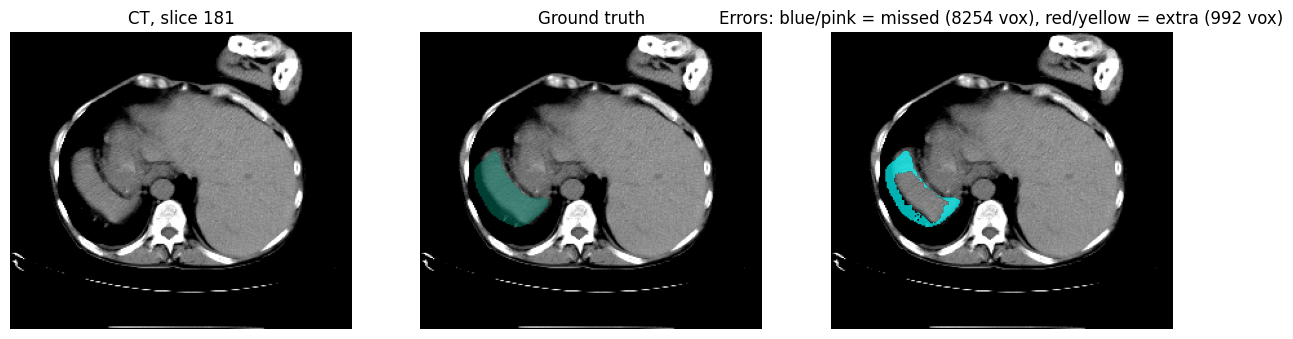

spleen_44.nii.gz: total missed 8254 voxels, total extra 992 voxels


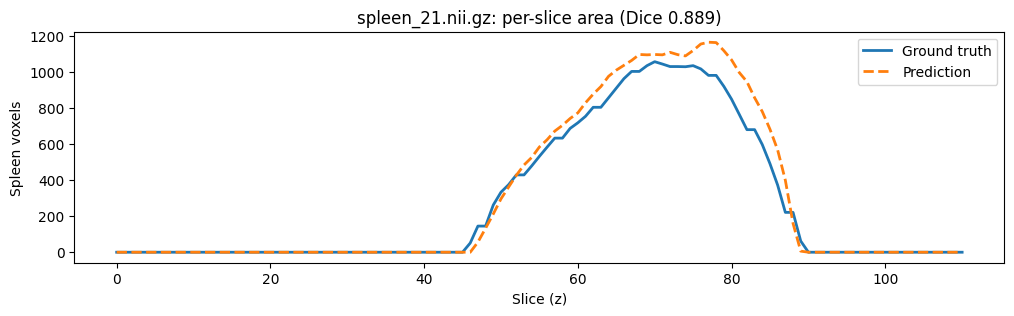

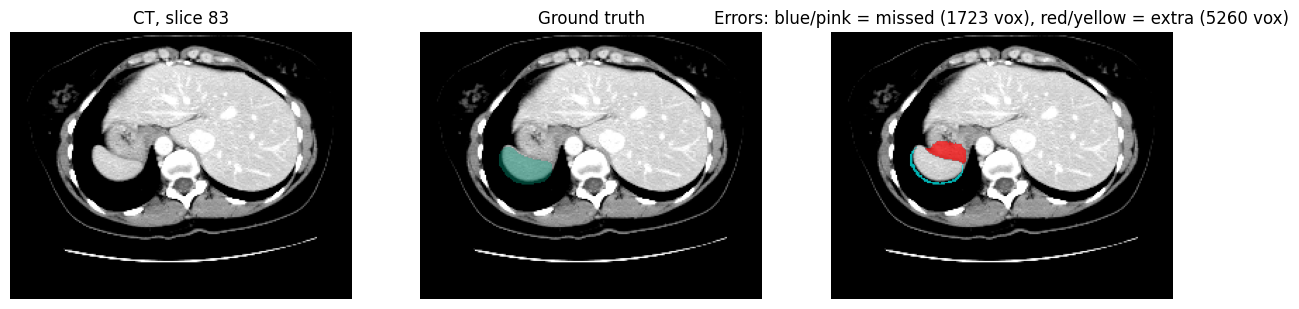

spleen_21.nii.gz: total missed 1723 voxels, total extra 5260 voxels


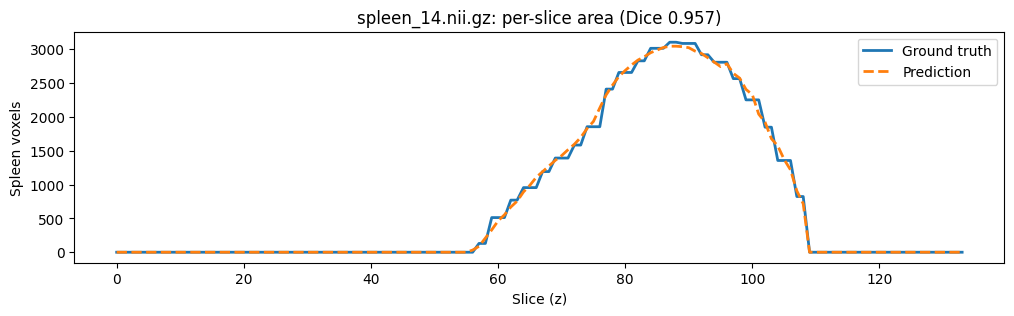

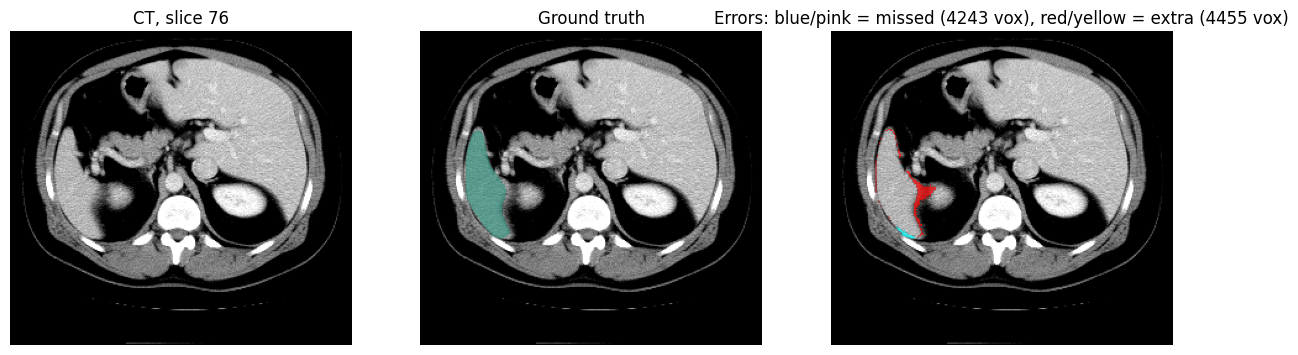

spleen_14.nii.gz: total missed 4243 voxels, total extra 4455 voxels


In [ ]:
def analyse_case(name):
    idx = [r["case"] for r in rows].index(name)
    img, gt, pr = test_outputs[idx]
    gt_area, pr_area = gt.sum(axis=(0, 1)), pr.sum(axis=(0, 1))

    plt.figure(figsize=(12, 3))
    plt.plot(gt_area, label="Ground truth", lw=2)
    plt.plot(pr_area, label="Prediction", lw=2, ls="--")
    plt.xlabel("Slice (z)"); plt.ylabel("Spleen voxels")
    plt.title(f"{name}: per-slice area (Dice {rows[idx]['dice']:.3f})"); plt.legend()
    plt.savefig(f"/content/drive/MyDrive/spleen_project/slices_{name[:-7]}.png", dpi=120)
    plt.show()

    err = (gt != pr).sum(axis=(0, 1))
    z = int(err.argmax())
    fn = (gt == 1) & (pr == 0)
    fp = (gt == 0) & (pr == 1)
    fig, ax = plt.subplots(1, 3, figsize=(15, 5))
    for a in ax: a.imshow(np.rot90(img[:, :, z]), cmap="gray"); a.axis("off")
    ax[0].set_title(f"CT, slice {z}")
    ax[1].imshow(np.rot90(np.ma.masked_where(gt[:, :, z] == 0, gt[:, :, z])), cmap="summer", alpha=0.5)
    ax[1].set_title("Ground truth")
    ax[2].imshow(np.rot90(np.ma.masked_where(~fn[:, :, z], fn[:, :, z])), cmap="cool", alpha=0.7)
    ax[2].imshow(np.rot90(np.ma.masked_where(~fp[:, :, z], fp[:, :, z])), cmap="autumn", alpha=0.7)
    ax[2].set_title(f"Errors: blue/pink = missed ({fn.sum()} vox), red/yellow = extra ({fp.sum()} vox)")
    plt.savefig(f"/content/drive/MyDrive/spleen_project/errors_{name[:-7]}.png", dpi=120)
    plt.show()
    print(f"{name}: total missed {fn.sum()} voxels, total extra {fp.sum()} voxels")

for case in ["spleen_44.nii.gz", "spleen_21.nii.gz", "spleen_14.nii.gz"]:
    analyse_case(case)


## Training curves

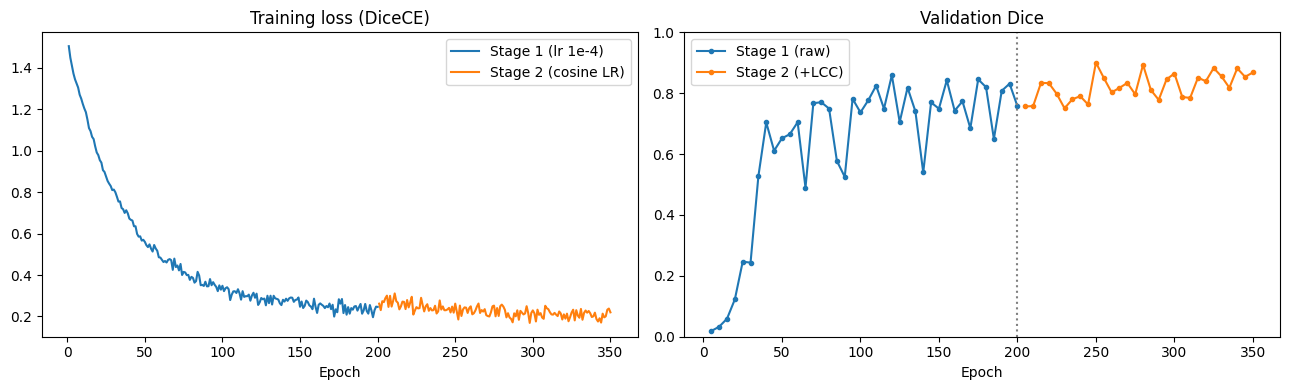

In [ ]:
H  = json.load(open(f"{RESULTS_DIR}/history.json"))
HF = json.load(open(f"{RESULTS_DIR}/history_ft.json"))
n1 = len(H["train_losses"])

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(range(1, n1 + 1), H["train_losses"], label="Stage 1 (lr 1e-4)")
ax[0].plot(range(n1 + 1, n1 + len(HF["losses"]) + 1), HF["losses"], label="Stage 2 (cosine LR)")
ax[0].set_title("Training loss (DiceCE)"); ax[0].set_xlabel("Epoch"); ax[0].legend()

ax[1].plot([5 * (i + 1) for i in range(len(H["val_dices"]))], H["val_dices"], "o-", ms=3, label="Stage 1 (raw)")
ax[1].plot([n1 + 5 * (i + 1) for i in range(len(HF["val_dices"]))], HF["val_dices"], "o-", ms=3, label="Stage 2 (+LCC)")
ax[1].axvline(n1, color="gray", ls=":")
ax[1].set_title("Validation Dice"); ax[1].set_xlabel("Epoch"); ax[1].set_ylim(0, 1); ax[1].legend()
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/training_curves.png", dpi=120)
plt.show()


## Inference pipeline

/usr/local/lib/python3.13/dist-packages/monai/utils/deprecate_utils.py:320: FutureWarning: monai.transforms.spatial.dictionary Orientationd.__init__:labels: Current default value of argument `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` was changed in version None from `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` to `labels=None`. Default value changed to None meaning that the transform now uses the 'space' of a meta-tensor, if applicable, to determine appropriate axis labels.
  warn_deprecated(argname, msg, warning_category)


spleen_1.nii.gz: 196.5 mL | 1.37 s
spleen_11.nii.gz: 335.6 mL | 3.93 s
spleen_15.nii.gz: 133.3 mL | 1.54 s


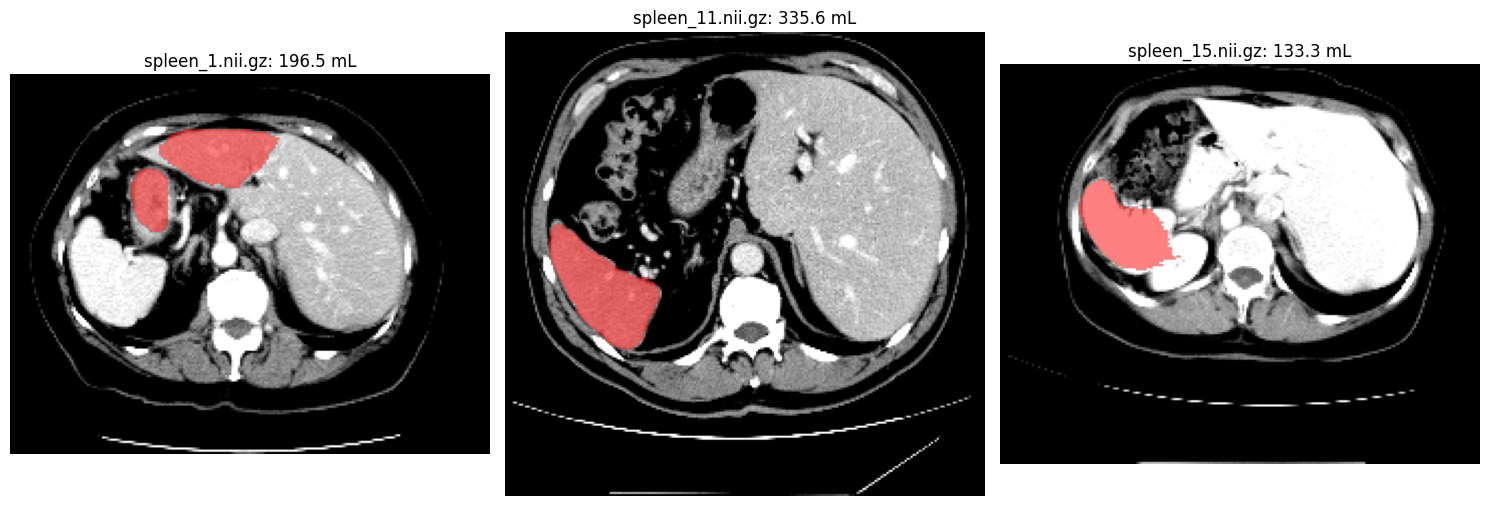

In [ ]:
infer_transforms = Compose(base_transforms(["image"], ("bilinear",)) + [EnsureTyped(keys=["image"])])
model.load_state_dict(torch.load(FT_DRIVE_PATH, map_location=device)); model.eval()

@torch.no_grad()
def predict_spleen(image_path):
    t = time.time()
    x = infer_transforms({"image": image_path})["image"].unsqueeze(0).to(device)
    out = sliding_window_inference(x, ROI_SIZE, 4, model, overlap=0.25)
    mask = lcc(torch.argmax(out[0], dim=0, keepdim=True))
    return {"spleen_volume_ml": round(mask.sum().item() * voxel_ml, 1),
            "inference_time_s": round(time.time() - t, 2),
            "image": x[0, 0].cpu().numpy(), "mask": mask[0].cpu().numpy()}

demo = []
for p in test_images[:3]:
    r = predict_spleen(p); demo.append((os.path.basename(p), r))
    print(f"{os.path.basename(p)}: {r['spleen_volume_ml']} mL | {r['inference_time_s']} s")

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a, (name, r) in zip(ax, demo):
    z = int(r["mask"].sum(axis=(0, 1)).argmax())
    a.imshow(np.rot90(r["image"][:, :, z]), cmap="gray")
    a.imshow(np.rot90(np.ma.masked_where(r["mask"][:, :, z] == 0, r["mask"][:, :, z])), cmap="autumn", alpha=0.5)
    a.set_title(f"{name}: {r['spleen_volume_ml']} mL"); a.axis("off")
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/inference_example.png", dpi=120)
plt.show()


Mask slices: 17 to 72 | volume 196.5 mL


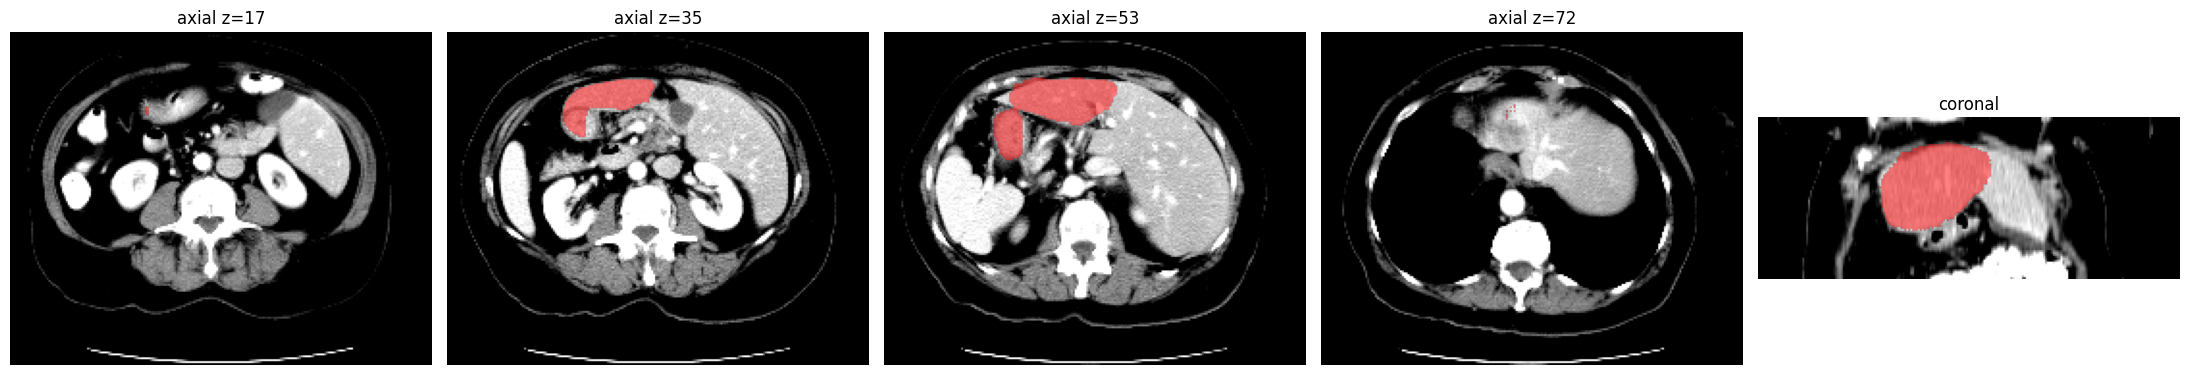

In [ ]:
r = predict_spleen(test_images[0])
img, m = r["image"], r["mask"]
zs = np.where(m.sum(axis=(0, 1)) > 0)[0]
print("Mask slices:", zs.min(), "to", zs.max(), "| volume", r["spleen_volume_ml"], "mL")

picks = np.linspace(zs.min(), zs.max(), 4).astype(int)
yc = int(m.sum(axis=(0, 2)).argmax())
fig, ax = plt.subplots(1, 5, figsize=(22, 5))
for a, z in zip(ax[:4], picks):
    a.imshow(np.rot90(img[:, :, z]), cmap="gray")
    a.imshow(np.rot90(np.ma.masked_where(m[:, :, z] == 0, m[:, :, z])), cmap="autumn", alpha=0.5)
    a.set_title(f"axial z={z}"); a.axis("off")
ax[4].imshow(np.rot90(img[:, yc, :]), cmap="gray")
ax[4].imshow(np.rot90(np.ma.masked_where(m[:, yc, :] == 0, m[:, yc, :])), cmap="autumn", alpha=0.5)
ax[4].set_title("coronal"); ax[4].axis("off")
plt.tight_layout(); plt.show()


## External validation: TotalSegmentator

In [ ]:
EXT_DIR = "/content/ext"
os.makedirs(EXT_DIR, exist_ok=True)
!wget -q --show-progress -O /content/ext/ts_small.zip "https://zenodo.org/records/10047263/files/Totalsegmentator_dataset_small_v201.zip?download=1"
!unzip -q -o /content/ext/ts_small.zip -d /content/ext/
!ls /content/ext | head; ls /content/ext/*/ | head


               /con   3%[                    ] 119.87M   535KB/s    eta 2h 0m  ^C
[/content/ext/ts_small.zip]
  End-of-central-directory signature not found.  Either this file is not
  a zipfile, or it constitutes one disk of a multi-part archive.  In the
  latter case the central directory and zipfile comment will be found on
  the last disk(s) of this archive.
unzip:  cannot find zipfile directory in one of /content/ext/ts_small.zip or
        /content/ext/ts_small.zip.zip, and cannot find /content/ext/ts_small.zip.ZIP, period.
ts_small.zip
ls: cannot access '/content/ext/*/': No such file or directory


In [ ]:
!rm -f /content/ext/ts_small.zip
!wget -q --show-progress -O /content/ext/ts_small.zip "https://www.dropbox.com/scl/fi/pee5yxebfxrhz007cbuy5/Totalsegmentator_dataset_small_v201.zip?rlkey=osvfk02jc4lw5gr6uhrldtb9e&dl=1"
!unzip -q -o /content/ext/ts_small.zip -d /content/ext/
!ls /content/ext | head; ls /content/ext/*/ | head


/content/ext/ts_sma 100%[===================>]   3.02G  17.9MB/s    in 3m 6s   
meta.csv
s0011
s0058
s0223
s0250
s0310
s0344
s0357
s0358
s0363
/content/ext/s0011/:
ct.nii.gz
segmentations

/content/ext/s0058/:
ct.nii.gz
segmentations

/content/ext/s0223/:
ct.nii.gz


In [ ]:
from monai.metrics import MeanIoU, compute_hausdorff_distance

cands = []
for ct in sorted(glob.glob(f"{EXT_DIR}/**/ct.nii.gz", recursive=True)):
    sp = os.path.join(os.path.dirname(ct), "segmentations", "spleen.nii.gz")
    if not os.path.exists(sp):
        continue
    m = nib.load(sp).get_fdata()
    zs = np.where(m.sum(axis=(0, 1)) > 0)[0]
    vol = m.sum() * np.prod(nib.load(sp).header.get_zooms()) / 1000
    if len(zs) and vol > 20 and zs.min() > 0 and zs.max() < m.shape[2] - 1:
        cands.append({"image": ct, "label": sp})
print(f"Scans with complete spleen: {len(cands)}")

ext_files = cands[:25]
ext_rows = []
with torch.no_grad():
    for f in ext_files:
        d = val_transforms(f)
        x, y = d["image"].unsqueeze(0).to(device), d["label"].unsqueeze(0).to(device)
        y = (y > 0.5).float()
        out = sliding_window_inference(x, ROI_SIZE, 4, model, overlap=0.25)
        p = lcc(torch.argmax(out, dim=1, keepdim=True)[0]).unsqueeze(0).float()
        p1, y1 = torch.cat([1 - p, p], 1), torch.cat([1 - y, y], 1)
        vp, vg = p.sum().item() * voxel_ml, y.sum().item() * voxel_ml
        hd = compute_hausdorff_distance(p1, y1, include_background=False, percentile=95, spacing=SPACING).item() if vp > 0 else float("nan")
        ext_rows.append(dict(case=f["image"].split("/")[-2],
                             dice=DiceMetric(include_background=False)(p1, y1).item(),
                             hd95_mm=hd, vol_pred_ml=vp, vol_gt_ml=vg,
                             vol_err_pct=100 * (vp - vg) / vg))
        r = ext_rows[-1]
        print(f"{r['case']:<10} Dice {r['dice']:.3f} | HD95 {r['hd95_mm']:6.1f} | {vp:6.1f} vs {vg:6.1f} mL ({r['vol_err_pct']:+.1f}%)")

d = np.array([r["dice"] for r in ext_rows])
print(f"\nExternal Dice: mean {d.mean():.3f} ± {d.std():.3f} | median {np.median(d):.3f} | failures (<0.5): {(d < 0.5).sum()}/{len(d)}")
print(f"Internal (MSD test) Dice was 0.908 ± 0.053")
json.dump(ext_rows, open(f"{RESULTS_DIR}/external_totalseg_metrics.json", "w"), indent=2)


Scans with complete spleen: 74
s0011      Dice 0.916 | HD95    3.6 |  185.6 vs  188.6 mL (-1.6%)
s0058      Dice 0.908 | HD95    8.1 |  485.8 vs  573.9 mL (-15.3%)
s0250      Dice 0.000 | HD95  301.0 |   20.4 vs  381.5 mL (-94.6%)
s0344      Dice 0.941 | HD95    3.0 |  254.4 vs  249.7 mL (+1.9%)
s0357      Dice 0.837 | HD95    7.5 |   49.0 vs   59.1 mL (-17.1%)
s0358      Dice 0.916 | HD95    4.7 |  204.0 vs  228.8 mL (-10.8%)
s0407      Dice 0.000 | HD95  239.2 |   24.7 vs  199.9 mL (-87.6%)
s0461      Dice 0.892 | HD95    9.0 |  338.3 vs  371.0 mL (-8.8%)
s0477      Dice 0.897 | HD95    8.5 |  182.3 vs  194.1 mL (-6.1%)
s0511      Dice 0.941 | HD95    2.5 |  167.7 vs  168.8 mL (-0.7%)
s0513      Dice 0.000 | HD95  196.7 |    1.3 vs  140.1 mL (-99.1%)
s0519      Dice 0.951 | HD95    2.9 |  242.4 vs  252.5 mL (-4.0%)
s0591      Dice 0.000 | HD95  220.4 |  184.2 vs  144.9 mL (+27.2%)
s0649      Dice 0.000 | HD95  303.8 |   43.7 vs   86.8 mL (-49.7%)
s0703      Dice 0.831 | HD95   20.4 |

In [ ]:
diag = []
with torch.no_grad():
    for f, r in zip(ext_files, ext_rows):
        ct_raw = nib.load(f["image"]); gt_raw = nib.load(f["label"]).get_fdata() > 0
        hu_spleen = float(ct_raw.get_fdata()[gt_raw].mean())
        z_mm = ct_raw.shape[2] * ct_raw.header.get_zooms()[2]

        d = val_transforms(f)
        x, y = d["image"].unsqueeze(0).to(device), (d["label"].unsqueeze(0).to(device) > 0.5).float()
        raw = torch.argmax(sliding_window_inference(x, ROI_SIZE, 4, model, overlap=0.25), dim=1, keepdim=True).float()
        inter = (raw * y).sum().item()
        dice_raw = 2 * inter / (raw.sum().item() + y.sum().item() + 1e-6)
        diag.append(dict(case=r["case"], dice=r["dice"], dice_raw=dice_raw,
                         hu_spleen=hu_spleen, scan_len_mm=z_mm))

print(f"{'case':<8}{'Dice':>7}{'Raw':>7}{'HU spl':>8}{'Len mm':>8}")
for g in sorted(diag, key=lambda g: g["dice"]):
    print(f"{g['case']:<8}{g['dice']:7.3f}{g['dice_raw']:7.3f}{g['hu_spleen']:8.0f}{g['scan_len_mm']:8.0f}")

ok  = [g for g in diag if g["dice"] >= 0.5]
bad = [g for g in diag if g["dice"] <  0.5]
for k in ["hu_spleen", "scan_len_mm", "dice_raw"]:
    print(f"{k:>12}: good {np.mean([g[k] for g in ok]):7.1f} | failed {np.mean([g[k] for g in bad]):7.1f}")
json.dump(diag, open(f"{RESULTS_DIR}/external_diagnostics.json", "w"), indent=2, default=float)


case       Dice    Raw  HU spl  Len mm
s0250     0.000  0.000     100     452
s0407     0.000  0.000     114     342
s0513     0.000  0.016      74     513
s0591     0.000  0.416     129     796
s0649     0.000  0.152      97     582
s0726     0.000  0.445     109     602
s0727     0.000  0.446     167     788
s0747     0.000  0.100      21     316
s0763     0.000  0.356     157     771
s0859     0.312  0.366      82     675
s0878     0.586  0.567      85     640
s0703     0.831  0.748      93     651
s0357     0.837  0.649      81     322
s0461     0.892  0.806     107     670
s0477     0.897  0.849      93     606
s0058     0.908  0.864      73     488
s0358     0.916  0.908      45     784
s0011     0.916  0.826      82     646
s0812     0.934  0.739     144     824
s0777     0.934  0.689     118     804
s0511     0.941  0.639      97     698
s0344     0.941  0.914      79     576
s0720     0.943  0.797      69     668
s0519     0.951  0.889      92     650
s0762     0.953  0.784   

## Multi-centre fine-tune

In [ ]:
from monai.data import PersistentDataset
import shutil

ts_rest  = cands[25:]
ts_val   = ts_rest[:5]
ts_train = ts_rest[5:]
mix_train = train_files + ts_train
mix_val   = val_files + ts_val
print(f"Train {len(mix_train)} (MSD {len(train_files)} + TS {len(ts_train)}) | "
      f"Val {len(mix_val)} (MSD {len(val_files)} + TS {len(ts_val)})")
json.dump({"ts_train": ts_train, "ts_val": ts_val, "ts_test": cands[:25]},
          open(f"{RESULTS_DIR}/splits_multicenter.json", "w"), indent=2)

def fix_label(d):
    d["label"] = (d["label"] > 0.5).float(); return d
from monai.transforms import Lambdad
mix_train_tf = Compose(list(train_transforms.transforms[:6]) + [Lambdad("label", lambda l: (l > 0.5).float())]
                       + list(train_transforms.transforms[6:]))
mix_val_tf   = Compose(list(val_transforms.transforms[:6]) + [Lambdad("label", lambda l: (l > 0.5).float())]
                       + list(val_transforms.transforms[6:]))

shutil.rmtree("/content/pcache", ignore_errors=True)
mtrain_ds = PersistentDataset(mix_train, mix_train_tf, cache_dir="/content/pcache/train")
mval_ds   = PersistentDataset(mix_val,   mix_val_tf,   cache_dir="/content/pcache/val")
mtrain_loader = DataLoader(mtrain_ds, batch_size=2, shuffle=True, num_workers=2)
mval_loader   = DataLoader(mval_ds,   batch_size=1, num_workers=2)

model.load_state_dict(torch.load(f"{RESULTS_DIR}/best_model_ft.pth", map_location=device))
from monai.losses import DiceCELoss
loss_fn   = DiceCELoss(to_onehot_y=True, softmax=True)
EPOCHS_MC = 100
optimizer = torch.optim.AdamW(model.parameters(), lr=5e-5, weight_decay=1e-5)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS_MC)
MC_PATH   = f"{RESULTS_DIR}/best_model_multicenter.pth"

def validate_mc():
    model.eval(); scores = []
    with torch.no_grad():
        for b in mval_loader:
            x, y = b["image"].to(device), b["label"].to(device)
            out  = sliding_window_inference(x, ROI_SIZE, 4, model, overlap=0.25)
            p    = lcc(torch.argmax(out, dim=1, keepdim=True)[0]).unsqueeze(0).float()
            inter = (p * y).sum().item()
            scores.append(2 * inter / (p.sum().item() + y.sum().item() + 1e-6))
    return float(np.mean(scores)), scores

best_mc, _ = validate_mc(); best_mc_ep = 0
print(f"Start (MSD model) on mixed val: {best_mc:.4f}")
torch.save(model.state_dict(), MC_PATH)

mc_hist = {"loss": [], "val": []}
t0 = time.time()
for ep in range(1, EPOCHS_MC + 1):
    model.train(); tot, n = 0.0, 0
    for b in mtrain_loader:
        x, y = b["image"].to(device), b["label"].to(device)
        optimizer.zero_grad(); loss = loss_fn(model(x), y); loss.backward(); optimizer.step()
        tot += loss.item(); n += 1
    scheduler.step(); mc_hist["loss"].append(tot / n)
    if ep % 5 == 0:
        v, per = validate_mc(); mc_hist["val"].append(v)
        if v > best_mc:
            best_mc, best_mc_ep = v, ep
            torch.save(model.state_dict(), MC_PATH)
        print(f"MC {ep:3d} | loss {tot/n:.4f} | val {v:.4f} (MSD {np.mean(per[:6]):.3f} / TS {np.mean(per[6:]):.3f}) "
              f"| best {best_mc:.4f} (ep {best_mc_ep}) | {(time.time()-t0)/60:.1f} min")
    json.dump(mc_hist, open(f"{RESULTS_DIR}/history_multicenter.json", "w"))
print(f"Done. Best mixed val {best_mc:.4f} at epoch {best_mc_ep}")


## Multi-centre fine-tune, clean run

Restarted the runtime for this part, so the setup cells are repeated.

In [ ]:
!pip install -q "monai[nibabel]>=1.3" scikit-image


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 74.6 MB/s eta 0:00:00


In [ ]:
import os, glob, json, random, time, shutil
import numpy as np, torch, nibabel as nib, matplotlib.pyplot as plt
from google.colab import drive
drive.mount("/content/drive")

from monai.apps import download_and_extract
from monai.utils import set_determinism
from monai.data import PersistentDataset, DataLoader
from monai.transforms import (Compose, LoadImaged, EnsureChannelFirstd, Orientationd, Spacingd,
    ScaleIntensityRanged, CropForegroundd, RandCropByPosNegLabeld, RandFlipd, RandRotate90d,
    RandShiftIntensityd, EnsureTyped, Lambdad, KeepLargestConnectedComponent)
from monai.networks.nets import UNet
from monai.networks.layers import Norm
from monai.losses import DiceCELoss
from monai.metrics import DiceMetric, compute_hausdorff_distance
from monai.inferers import sliding_window_inference

SEED = 42; set_determinism(seed=SEED)
device = torch.device("cuda")
RESULTS_DIR = "/content/drive/MyDrive/spleen_project"
DATA_DIR = "/content/data"; os.makedirs(DATA_DIR, exist_ok=True)
HU_MIN, HU_MAX = -57, 164
SPACING = (1.5, 1.5, 2.0); ROI_SIZE = (96, 96, 96)
voxel_ml = np.prod(SPACING) / 1000.0

data_root = f"{DATA_DIR}/Task09_Spleen"
if not os.path.exists(data_root):
    download_and_extract("https://msd-for-monai.s3-us-west-2.amazonaws.com/Task09_Spleen.tar",
                         f"{DATA_DIR}/Task09_Spleen.tar", DATA_DIR)
images = sorted(glob.glob(f"{data_root}/imagesTr/*.nii.gz"))
labels = sorted(glob.glob(f"{data_root}/labelsTr/*.nii.gz"))

data = [{"image": i, "label": l} for i, l in zip(images, labels)]
random.Random(SEED).shuffle(data)
test_files, val_files, train_files = data[:6], data[6:12], data[12:]
print("MSD test:", [os.path.basename(f["image"]) for f in test_files])

def base(keys, modes):
    t = [LoadImaged(keys=keys), EnsureChannelFirstd(keys=keys)]
    if "label" in keys:
        t.append(Lambdad("label", lambda l: (l > 0.5).float()))
    return t + [Orientationd(keys=keys, axcodes="RAS"),
                Spacingd(keys=keys, pixdim=SPACING, mode=modes),
                ScaleIntensityRanged(keys=["image"], a_min=HU_MIN, a_max=HU_MAX, b_min=0.0, b_max=1.0, clip=True),
                CropForegroundd(keys=keys, source_key="image", allow_smaller=True)]
K = ["image", "label"]
train_tf = Compose(base(K, ("bilinear", "nearest")) + [
    RandCropByPosNegLabeld(keys=K, label_key="label", spatial_size=ROI_SIZE, pos=1, neg=1,
                           num_samples=4, image_key="image", image_threshold=0),
    RandFlipd(keys=K, spatial_axis=[0], prob=0.1), RandFlipd(keys=K, spatial_axis=[1], prob=0.1),
    RandFlipd(keys=K, spatial_axis=[2], prob=0.1), RandRotate90d(keys=K, prob=0.1, max_k=3),
    RandShiftIntensityd(keys=["image"], offsets=0.1, prob=0.5), EnsureTyped(keys=K)])
eval_tf = Compose(base(K, ("bilinear", "nearest")) + [EnsureTyped(keys=K)])

model = UNet(spatial_dims=3, in_channels=1, out_channels=2, channels=(16, 32, 64, 128, 256),
             strides=(2, 2, 2, 2), num_res_units=2, norm=Norm.BATCH).to(device)
model.load_state_dict(torch.load(f"{RESULTS_DIR}/best_model_ft.pth", map_location=device))
lcc = KeepLargestConnectedComponent(applied_labels=[1])
print("Setup done")


Mounted at /content/drive


Task09_Spleen.tar: 1.50GB [02:38, 10.2MB/s]                            

2026-10-14 17:58:46,865 - INFO - Downloaded: /content/data/Task09_Spleen.tar
2026-10-14 17:58:46,866 - INFO - Writing into directory: /content/data.



/usr/local/lib/python3.13/dist-packages/monai/apps/utils.py:273: UserWarning: No hash value provided for /tmp/tmpioqval_q/Task09_Spleen.tar; file integrity is NOT verified.
  if not check_hash(tmp_name, hash_val, hash_type):


MSD test: ['spleen_20.nii.gz', 'spleen_14.nii.gz', 'spleen_21.nii.gz', 'spleen_61.nii.gz', 'spleen_44.nii.gz', 'spleen_41.nii.gz']


/usr/local/lib/python3.13/dist-packages/monai/utils/deprecate_utils.py:320: FutureWarning: monai.transforms.spatial.dictionary Orientationd.__init__:labels: Current default value of argument `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` was changed in version None from `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` to `labels=None`. Default value changed to None meaning that the transform now uses the 'space' of a meta-tensor, if applicable, to determine appropriate axis labels.
  warn_deprecated(argname, msg, warning_category)


Setup done


In [ ]:
EXT_DIR = "/content/ext"; os.makedirs(EXT_DIR, exist_ok=True)
if not glob.glob(f"{EXT_DIR}/**/ct.nii.gz", recursive=True):
    !wget -q --show-progress -O /content/ext/ts_small.zip "https://www.dropbox.com/scl/fi/pee5yxebfxrhz007cbuy5/Totalsegmentator_dataset_small_v201.zip?rlkey=osvfk02jc4lw5gr6uhrldtb9e&dl=1"
    !unzip -q -o /content/ext/ts_small.zip -d /content/ext/ && rm /content/ext/ts_small.zip

cands = []
for ct in sorted(glob.glob(f"{EXT_DIR}/**/ct.nii.gz", recursive=True)):
    sp = os.path.join(os.path.dirname(ct), "segmentations", "spleen.nii.gz")
    if not os.path.exists(sp): continue
    lab = nib.load(sp); m = lab.get_fdata()
    zs = np.where(m.sum(axis=(0, 1)) > 0)[0]
    vol = m.sum() * np.prod(lab.header.get_zooms()) / 1000
    if len(zs) and vol > 20 and zs.min() > 0 and zs.max() < m.shape[2] - 1:
        cands.append({"image": ct, "label": sp})

ts_test  = cands[:25]
ts_val   = cands[25:30]
ts_train = cands[30:]
print(f"TotalSeg complete-spleen scans: {len(cands)} -> test {len(ts_test)} | val {len(ts_val)} | train {len(ts_train)}")
print("First test case:", ts_test[0]["image"].split("/")[-2])
json.dump({"ts_train": ts_train, "ts_val": ts_val, "ts_test": ts_test},
          open(f"{RESULTS_DIR}/splits_multicenter.json", "w"), indent=2)


/content/ext/ts_sma 100%[===================>]   3.02G  12.2MB/s    in 3m 26s  
TotalSeg complete-spleen scans: 74 -> test 25 | val 5 | train 44
First test case: s0011


In [ ]:
from monai.transforms import SpatialPadd

def base(keys, modes):
    t = [LoadImaged(keys=keys), EnsureChannelFirstd(keys=keys)]
    if "label" in keys:
        t.append(Lambdad("label", lambda l: (l > 0.5).float()))
    return t + [Orientationd(keys=keys, axcodes="RAS"),
                Spacingd(keys=keys, pixdim=SPACING, mode=modes),
                ScaleIntensityRanged(keys=["image"], a_min=HU_MIN, a_max=HU_MAX, b_min=0.0, b_max=1.0, clip=True),
                CropForegroundd(keys=keys, source_key="image", allow_smaller=True,
                                start_coord_key=None, end_coord_key=None)]

train_tf = Compose(base(K, ("bilinear", "nearest")) + [
    SpatialPadd(keys=K, spatial_size=ROI_SIZE),
    RandCropByPosNegLabeld(keys=K, label_key="label", spatial_size=ROI_SIZE, pos=1, neg=1,
                           num_samples=4, image_key="image", image_threshold=0),
    RandFlipd(keys=K, spatial_axis=[0], prob=0.1), RandFlipd(keys=K, spatial_axis=[1], prob=0.1),
    RandFlipd(keys=K, spatial_axis=[2], prob=0.1), RandRotate90d(keys=K, prob=0.1, max_k=3),
    RandShiftIntensityd(keys=["image"], offsets=0.1, prob=0.5), EnsureTyped(keys=K)])
eval_tf = Compose(base(K, ("bilinear", "nearest")) + [EnsureTyped(keys=K)])

model.load_state_dict(torch.load(f"{RESULTS_DIR}/best_model_ft.pth", map_location=device))
print("transforms fixed, model reset")


transforms fixed, model reset


In [ ]:
mix_train = train_files + ts_train
mix_val   = val_files + ts_val
print(f"Train {len(mix_train)} | Val {len(mix_val)}")

shutil.rmtree("/content/pcache", ignore_errors=True)
tr_loader = DataLoader(PersistentDataset(mix_train, train_tf, cache_dir="/content/pcache/tr"),
                       batch_size=2, shuffle=True, num_workers=2)
va_loader = DataLoader(PersistentDataset(mix_val, eval_tf, cache_dir="/content/pcache/va"),
                       batch_size=1, num_workers=2)

loss_fn = DiceCELoss(to_onehot_y=True, softmax=True)
EPOCHS = 80
optimizer = torch.optim.AdamW(model.parameters(), lr=5e-5, weight_decay=1e-5)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
MC_PATH = f"{RESULTS_DIR}/best_model_multicenter.pth"

def dice_of(p, y):
    return 2 * (p * y).sum().item() / (p.sum().item() + y.sum().item() + 1e-6)

def validate():
    model.eval(); s = []
    with torch.no_grad():
        for b in va_loader:
            x, y = b["image"].to(device), b["label"].to(device)
            out = sliding_window_inference(x, ROI_SIZE, 4, model, overlap=0.25)
            p = lcc(torch.argmax(out, 1, keepdim=True)[0]).unsqueeze(0).float()
            s.append(dice_of(p, y))
    return float(np.mean(s)), s

best, per = validate(); best_ep = 0
print(f"Start (old model) mixed val {best:.4f} | MSD {np.mean(per[:6]):.3f} | TS {np.mean(per[6:]):.3f}")
torch.save(model.state_dict(), MC_PATH)

hist = {"loss": [], "val": [], "val_msd": [], "val_ts": []}
t0 = time.time()
for ep in range(1, EPOCHS + 1):
    model.train(); tot, n = 0.0, 0
    for b in tr_loader:
        x, y = b["image"].to(device), b["label"].to(device)
        optimizer.zero_grad(); loss = loss_fn(model(x), y); loss.backward(); optimizer.step()
        tot += loss.item(); n += 1
    scheduler.step(); hist["loss"].append(tot / n)
    if ep % 5 == 0:
        v, per = validate()
        hist["val"].append(v); hist["val_msd"].append(float(np.mean(per[:6]))); hist["val_ts"].append(float(np.mean(per[6:])))
        if v > best:
            best, best_ep = v, ep; torch.save(model.state_dict(), MC_PATH)
        print(f"MC {ep:3d} | loss {tot/n:.4f} | val {v:.4f} (MSD {hist['val_msd'][-1]:.3f} / TS {hist['val_ts'][-1]:.3f}) "
              f"| best {best:.4f} (ep {best_ep}) | {(time.time()-t0)/60:.1f} min")
    else:
        print(f"MC {ep:3d} | loss {tot/n:.4f} | {(time.time()-t0)/60:.1f} min")
    json.dump(hist, open(f"{RESULTS_DIR}/history_multicenter.json", "w"))
print(f"Done. Best mixed val {best:.4f} at epoch {best_ep}")


Train 73 | Val 11
Start (old model) mixed val 0.7924 | MSD 0.901 | TS 0.663
MC   1 | loss 0.2936 | 6.3 min
MC   2 | loss 0.2543 | 7.1 min
MC   3 | loss 0.2704 | 7.9 min
MC   4 | loss 0.2521 | 8.7 min
MC   5 | loss 0.2846 | val 0.8061 (MSD 0.775 / TS 0.844) | best 0.8061 (ep 5) | 9.8 min
MC   6 | loss 0.2589 | 10.6 min
MC   7 | loss 0.2416 | 11.4 min
MC   8 | loss 0.2593 | 12.1 min
MC   9 | loss 0.2702 | 12.9 min
MC  10 | loss 0.2547 | val 0.8306 (MSD 0.788 / TS 0.882) | best 0.8306 (ep 10) | 14.0 min
MC  11 | loss 0.2224 | 14.7 min
MC  12 | loss 0.2774 | 15.5 min
MC  13 | loss 0.2854 | 16.2 min
MC  14 | loss 0.2879 | 17.0 min
MC  15 | loss 0.2478 | val 0.7734 (MSD 0.813 / TS 0.726) | best 0.8306 (ep 10) | 18.1 min
MC  16 | loss 0.2393 | 18.8 min
MC  17 | loss 0.2559 | 19.6 min
MC  18 | loss 0.2655 | 20.3 min
MC  19 | loss 0.2868 | 21.0 min
MC  20 | loss 0.2525 | val 0.8762 (MSD 0.842 / TS 0.917) | best 0.8762 (ep 20) | 22.2 min
MC  21 | loss 0.2469 | 22.9 min
MC  22 | loss 0.2542 | 23.

## Final evaluation

In [ ]:
def evaluate(files, weights):
    model.load_state_dict(torch.load(weights, map_location=device)); model.eval()
    rows = []
    with torch.no_grad():
        for f in files:
            d = eval_tf(f)
            x, y = d["image"].unsqueeze(0).to(device), d["label"].unsqueeze(0).to(device)
            out = sliding_window_inference(x, ROI_SIZE, 4, model, overlap=0.25)
            p = lcc(torch.argmax(out, 1, keepdim=True)[0]).unsqueeze(0).float()
            p1, y1 = torch.cat([1 - p, p], 1), torch.cat([1 - y, y], 1)
            vp, vg = p.sum().item() * voxel_ml, y.sum().item() * voxel_ml
            hd = compute_hausdorff_distance(p1, y1, include_background=False, percentile=95,
                                            spacing=SPACING).item() if vp > 0 else float("nan")
            rows.append(dict(case=f["image"].split("/")[-2] if "ct.nii" in f["image"] else os.path.basename(f["image"]),
                             dice=dice_of(p, y), hd95=hd, vol_err_pct=100 * (vp - vg) / vg))
    return rows

def summary(rows):
    d = np.array([r["dice"] for r in rows]); e = np.abs([r["vol_err_pct"] for r in rows])
    return (f"Dice {d.mean():.3f} ± {d.std():.3f} | median {np.median(d):.3f} | "
            f"fail(<0.5) {(d < 0.5).sum()}/{len(d)} | |vol err| median {np.median(e):.1f}%")

results = {}
for tag, w in [("baseline (MSD only)", f"{RESULTS_DIR}/best_model_ft.pth"),
               ("multicenter",         MC_PATH)]:
    results[tag] = {"msd_test": evaluate(test_files, w), "ts_test": evaluate(ts_test, w)}
    print(f"\n=== {tag} ===")
    print("  MSD test (n=6)      :", summary(results[tag]["msd_test"]))
    print("  TotalSeg test (n=25):", summary(results[tag]["ts_test"]))

json.dump(results, open(f"{RESULTS_DIR}/multicenter_comparison.json", "w"), indent=2, default=float)


/usr/local/lib/python3.13/dist-packages/monai/utils/deprecate_utils.py:220: FutureWarning: monai.metrics.utils get_mask_edges:always_return_as_numpy: Argument `always_return_as_numpy` has been deprecated since version 1.5.0. It will be removed in version 1.7.0. The option is removed and the return type will always be equal to the input type.
  warn_deprecated(argname, msg, warning_category)



=== baseline (MSD only) ===
  MSD test (n=6)      : Dice 0.908 ± 0.053 | median 0.933 | fail(<0.5) 0/6 | |vol err| median 5.8%
  TotalSeg test (n=25): Dice 0.548 ± 0.431 | median 0.837 | fail(<0.5) 10/25 | |vol err| median 15.3%

=== multicenter ===
  MSD test (n=6)      : Dice 0.924 ± 0.043 | median 0.938 | fail(<0.5) 0/6 | |vol err| median 2.3%
  TotalSeg test (n=25): Dice 0.895 ± 0.106 | median 0.931 | fail(<0.5) 1/25 | |vol err| median 4.6%
